In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats 

In [4]:
%pip install numpy pandas matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\jumana zainuddeen\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
data=pd.read_csv(r"C:\Users\jumana zainuddeen\DAV\student_performance_dataset.csv")
df=pd.DataFrame(data)
print(df)

     student_id  gender  study_time_hours  attendance_percent  sleep_hours  \
0             1    Male               4.0                98.0          6.5   
1             2  Female               6.3               100.0          5.7   
2             3    Male               4.9                85.3          7.9   
3             4    Male               2.6                77.5          8.0   
4             5    Male               2.2                89.6          4.6   
..          ...     ...               ...                 ...          ...   
995         996    Male               2.8                75.4          8.2   
996         997    Male               6.7                88.4          7.1   
997         998  Female               2.6                84.5          8.0   
998         999  Female               4.6                85.3          8.1   
999        1000    Male               3.9                77.4          6.1   

    parental_education internet_access extracurricular_activiti

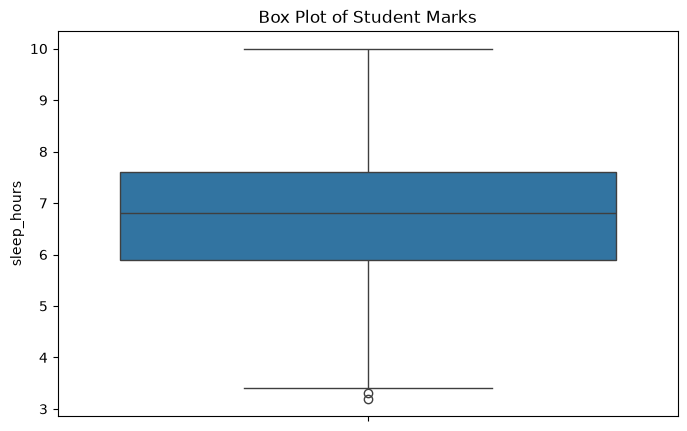

In [3]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['sleep_hours'])

plt.title("Box Plot of Student Marks")
plt.ylabel("sleep_hours")

plt.show()

In [6]:
# Step 1: Calculate Q1 and Q3
Q1 = df['final_exam_score'].quantile(0.25)
Q3 = df['final_exam_score'].quantile(0.75)

print("Q1 =", Q1)
print("Q3 =", Q3)

# Step 2: Calculate IQR
IQR = Q3 - Q1

print("IQR =", IQR)

# Step 3: Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)
print("Upper Limit =", upper_limit)

# Step 4: Identify outliers
outliers_iqr = df[
    (df['final_exam_score'] < lower_limit) |
    (df['final_exam_score'] > upper_limit)
]

print("Outliers detected using IQR:")
print(outliers_iqr)

Q1 = 76.07499999999999
Q3 = 91.525
IQR = 15.450000000000017
Lower Limit = 52.89999999999996
Upper Limit = 114.70000000000003
Outliers detected using IQR:
     student_id gender  study_time_hours  attendance_percent  sleep_hours  \
147         148   Male               1.7                83.5          5.7   

    parental_education internet_access extracurricular_activities  \
147            Masters             Yes                        Yes   

    part_time_job  previous_grade  final_exam_score final_grade  
147           Yes            59.2              46.8           F  


In [9]:
df['final_exam_score'] = df['final_exam_score'].clip(
    lower=lower_limit,
    upper=upper_limit
)

print(df[['sleep_hours', 'final_exam_score']])

     sleep_hours  final_exam_score
0            6.5             100.0
1            5.7             100.0
2            7.9              97.3
3            8.0              83.8
4            4.6              68.3
..           ...               ...
995          8.2              70.7
996          7.1              99.5
997          8.0              79.2
998          8.1              82.2
999          6.1              70.4

[1000 rows x 2 columns]


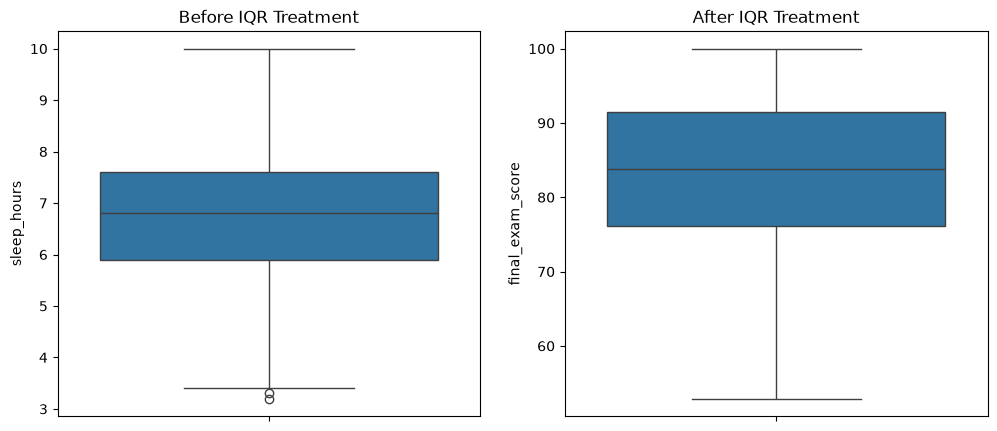

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['sleep_hours'], ax=axes[0])
axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['final_exam_score'], ax=axes[1])
axes[1].set_title("After IQR Treatment")

plt.show()

In [14]:
df['Z_score'] = stats.zscore(df['sleep_hours'])

print(df[['sleep_hours', 'Z_score']])

     sleep_hours   Z_score
0            6.5 -0.248976
1            5.7 -0.914022
2            7.9  0.914853
3            8.0  0.997984
4            4.6 -1.828459
..           ...       ...
995          8.2  1.164245
996          7.1  0.249808
997          8.0  0.997984
998          8.1  1.081114
999          6.1 -0.581499

[1000 rows x 2 columns]
